# **Predict Late Deliveries**

- ## Importing Modules

In [202]:
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from scipy.stats import t
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

- ### Dataset

In [203]:
data = pd.read_csv("set_b.csv")
data

,record_id,distance,load,traffic,staff,group,late
0,1,68.12,42.71,39.14,45.98,G2,1
1,2,38.47,65.08,58.80,56.38,G1,1
2,3,64.10,43.99,36.86,53.47,G2,0
3,4,53.09,41.44,55.36,64.72,G1,1
4,5,44.67,51.95,53.44,54.86,G1,1
...,...,...,...,...,...,...,...
300,1,68.12,42.71,39.14,45.98,G2,1
301,2,38.47,65.08,58.80,56.38,G1,1
302,3,64.10,43.99,36.86,53.47,G2,0
303,4,53.09,41.44,55.36,64.72,G1,1


- #### **Section A — Technical Work**

In [204]:
# Checking Duplicates
data.duplicated().sum()

np.int64(5)

In [205]:
# Dropping the duplicates
data.drop_duplicates(inplace= True)
data.duplicated().sum()

np.int64(0)

In [206]:
fit, test = train_test_split(
    data,
    test_size=0.20,
    stratify=data["late"],
    random_state=42
)

fit, val = train_test_split(
    fit,
    test_size=0.20,
    stratify=fit["late"],
    random_state=42
)

In [207]:
# Distance
distance = fit["distance"].dropna()
print(f"Observed n: ", distance.count())
print(f"Mean Distance: ", distance.mean())
print(f"Median Distance: ", distance.median())
print(f"Sample standard deviation(ddof = 1): ", distance.std(ddof=1))

Observed n:  184
Mean Distance:  49.74440217391305
Median Distance:  50.2
Sample standard deviation(ddof = 1):  10.835872254207478


Text(0, 0.5, 'Frequency')

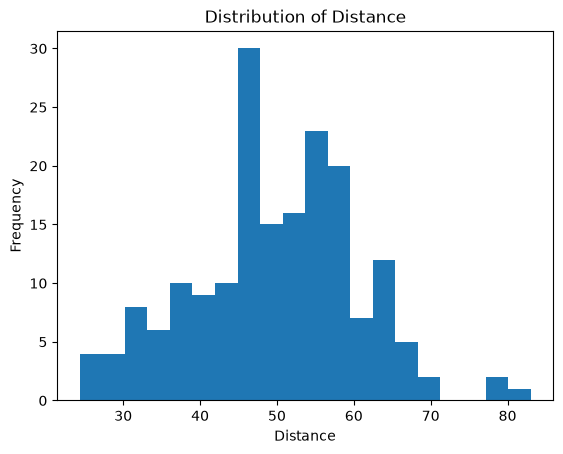

In [ ]:
# Plotting
plt.hist(distance, bins=20)
plt.title("Distribution of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")

In [209]:
# Welch T-test
g1 = fit[
    (fit["group"] == "G1") &
    (fit["distance"].notna())
]["distance"]

g2 = fit[
    (fit["group"] == "G2") &
    (fit["distance"].notna())
]["distance"]

result = ttest_ind(
    g1,
    g2,
    equal_var=False
)

print("G1 count:", len(g1))
print("G2 count:", len(g2))
print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)

G1 count: 104
G2 count: 80
T-statistic: 0.7061612423464614
P-value: 0.48105881393425975


In [210]:
# Confidence Interval
n = len(distance)
mean = distance.mean()
sem = distance.sem()

ci = t.interval(
    0.95,
    df=n-1,
    loc=mean,
    scale=sem
)
print("95% CI:", ci)

95% CI: (np.float64(48.16829889365107), np.float64(51.320505454175034))


In [211]:
# Linear Algebra
X = fit[["distance", "traffic"]].dropna().values
print("n =", len(X))

n = 184


In [212]:
# Data Preprocessing
print("Shape:", data.shape)
print("Duplicates:", data.duplicated().sum())
print("Missing values:")
print(data.isna().sum())

clean = data.drop_duplicates()

print("Clean shape:", clean.shape)
print("Unique IDs:", clean["record_id"].nunique())

Shape: (300, 7)
Duplicates: 0
Missing values:
record_id     0
distance     15
load         15
traffic       0
staff         0
group         0
late          0
dtype: int64
Clean shape: (300, 7)
Unique IDs: 300


In [214]:
# Assigning the Target variable
x = data.drop("late", axis = 1)
y = data["late"]

In [215]:
# train-test split
x_test, x_train, y_test, y_train = train_test_split(x,y, test_size= 0.2, random_state= 42, stratify= y)